In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft
from PIL import Image

## Aufgabenstellung

Bestimme von dem Bild `img_a2_mc2_vta_hs25.bmp` die Fouriertransformierte. 

Wende auf die transformierten Daten je ein:
- **Tiefpassfilter**
- **Hochpassfilter**

an und untersuche die Auswirkungen auf das rekonstruierte Bild.

Bild einlesen und sichergestellt, dass es sich um ein graustufenbild handelt.  

In [2]:
bild_pfad = r'C:\Users\lovas\OneDrive\Desktop\FHNW_Data_SCience\HS_2025\VTA\mc2_vta_hs25-1763972926\img_a2_mc2_vta_hs25.bmp'
img = Image.open(bild_pfad)
img_array = np.array(img)

# Prüfe ob Farbbild oder Graustufenbild
if len(img_array.shape) == 3:
    # Farbbild → Konvertiere zu Graustufen (verwende nur ersten Kanal oder Durchschnitt)
    img_gray = img_array[:, :, 0]  # Nimm ersten Kanal (meist sind alle gleich bei Graustufen-BMPs)
    print(f"\n✓ Bild eingelesen: {bild_pfad} (Farbbild → Graustufen konvertiert)")
elif len(img_array.shape) == 2:
    # Bereits Graustufenbild
    img_gray = img_array
    print(f"\n✓ Bild eingelesen: {bild_pfad} (Graustufenbild)")
else:
    raise ValueError(f"Unerwartete Bildform: {img_array.shape}")

print(f"Bildgrösse: {img_gray.shape[0]} × {img_gray.shape[1]} Pixel")
print(f"Wertebereich: [{img_gray.min():.1f}, {img_gray.max():.1f}]")


✓ Bild eingelesen: C:\Users\lovas\OneDrive\Desktop\FHNW_Data_SCience\HS_2025\VTA\mc2_vta_hs25-1763972926\img_a2_mc2_vta_hs25.bmp (Farbbild → Graustufen konvertiert)
Bildgrösse: 960 × 1280 Pixel
Wertebereich: [0.0, 255.0]


## Methodik

### Fouriertransformation
Das Bild wird mittels 2D-FFT in den Frequenzraum transformiert:
$$F(u,v) = \mathcal{F}\{f(x,y)\}$$

In [3]:
# 2D-FFT berechnen
F = fft.fft2(img_gray)

# Shift: DC-Komponente in die Mitte
F_shifted = fft.fftshift(F)

# Amplitudenspektrum
amplitude = np.abs(F_shifted)
amplitude_log = np.log10(amplitude + 1)  # Log-Skalierung für Visualisierung

print(f"FFT-Größe: {F_shifted.shape}")

FFT-Größe: (960, 1280)


### Filter im Frequenzraum

**Tiefpassfilter (Low-pass):**
- Lässt **niedrige Frequenzen** durch (glatte Bereiche, grobe Strukturen)
- Blockiert **hohe Frequenzen** (Details, Kanten, Rauschen)
- **Kreisförmiger Filter**: $H_{LP}(u,v) = \begin{cases} 1 & \text{wenn } \sqrt{(u-u_0)^2 + (v-v_0)^2} \leq r \\ 0 & \text{sonst} \end{cases}$

In [4]:
# Bildgrösse
rows, cols = img_gray.shape
crow, ccol = rows // 2, cols // 2  # Zentrum

# Erstelle Distanzmatrix vom Zentrum
y, x = np.ogrid[:rows, :cols]
distance = np.sqrt((x - ccol)**2 + (y - crow)**2)

# TIEFPASSFILTER: Lässt niedrige Frequenzen durch
# Radius für Tiefpass (kleinerer Radius = stärkere Glättung)
radius_lowpass = 50  # Pixel

lowpass_filter = np.zeros((rows, cols))
lowpass_filter[distance <= radius_lowpass] = 1

print(f"\nTiefpassfilter:")
print(f"Radius: {radius_lowpass} Pixel")
print(f"Durchgelassene Frequenzen: {np.sum(lowpass_filter)} / {rows*cols}")


Tiefpassfilter:
Radius: 50 Pixel
Durchgelassene Frequenzen: 7845.0 / 1228800


**Hochpassfilter (High-pass):**
- Blockiert **niedrige Frequenzen** (glatte Bereiche)
- Lässt **hohe Frequenzen** durch (Details, Kanten)
- **Kreisförmiger Filter**: $H_{HP}(u,v) = \begin{cases} 0 & \text{wenn } \sqrt{(u-u_0)^2 + (v-v_0)^2} \leq r \\ 1 & \text{sonst} \end{cases}$

In [5]:
# Hochpassfilter: Blockiert niedrige Frequenzen
# Radius für Hochpass (grösserer Radius = mehr Details bleiben)
radius_highpass = 50  # Pixel

highpass_filter = np.ones((rows, cols))
highpass_filter[distance <= radius_highpass] = 0

print(f"\nHochpassfilter:")
print(f"Radius: {radius_highpass} Pixel")
print(f"Durchgelassene Frequenzen: {np.sum(highpass_filter)} / {rows*cols}")


Hochpassfilter:
Radius: 50 Pixel
Durchgelassene Frequenzen: 1220955.0 / 1228800


## Wahl der Filterradien

Nach experimentellem Testen verschiedener Radius-Werte (10, 20, 30, 40, 50, 60 Pixel) wurde **Radius = 50 Pixel** gewählt, da dieser die beste Balance zwischen Filtereffekt und Bildqualität bietet:

- **Kleinere Radien** (10-30): Sehr starker Effekt, aber zu viel Information geht verloren
- **Radius 50**: Guter Kompromiss - klare Filtereffekte bleiben sichtbar
- **Grössere Radien** (60+): Zu schwacher Effekt, kaum Unterschied zum Original

In [6]:
# Tiefpassfilter anwenden
F_lowpass = F_shifted * lowpass_filter

# Hochpassfilter anwenden
F_highpass = F_shifted * highpass_filter

Die Fouriertransformation wird umgekehrt.

In [7]:
# Shift zurück
F_lowpass_shifted = fft.ifftshift(F_lowpass)
F_highpass_shifted = fft.ifftshift(F_highpass)

# Inverse FFT
img_lowpass = fft.ifft2(F_lowpass_shifted)
img_highpass = fft.ifft2(F_highpass_shifted)

# Realteil nehmen (Imaginärteil sollte vernachlässigbar sein)
img_lowpass = np.real(img_lowpass)
img_highpass = np.real(img_highpass)

print("Inverse FFT berechnet")
print(f"Tiefpass - Wertebereich: [{img_lowpass.min():.1f}, {img_lowpass.max():.1f}]")
print(f"Hochpass - Wertebereich: [{img_highpass.min():.1f}, {img_highpass.max():.1f}]")

# Normalisiere Hochpass für bessere Visualisierung
img_highpass_norm = img_highpass - img_highpass.min()
img_highpass_norm = img_highpass_norm / img_highpass_norm.max() * 255

Inverse FFT berechnet
Tiefpass - Wertebereich: [-37.3, 280.2]
Hochpass - Wertebereich: [-169.0, 191.3]


## Visualisieren des Bildes

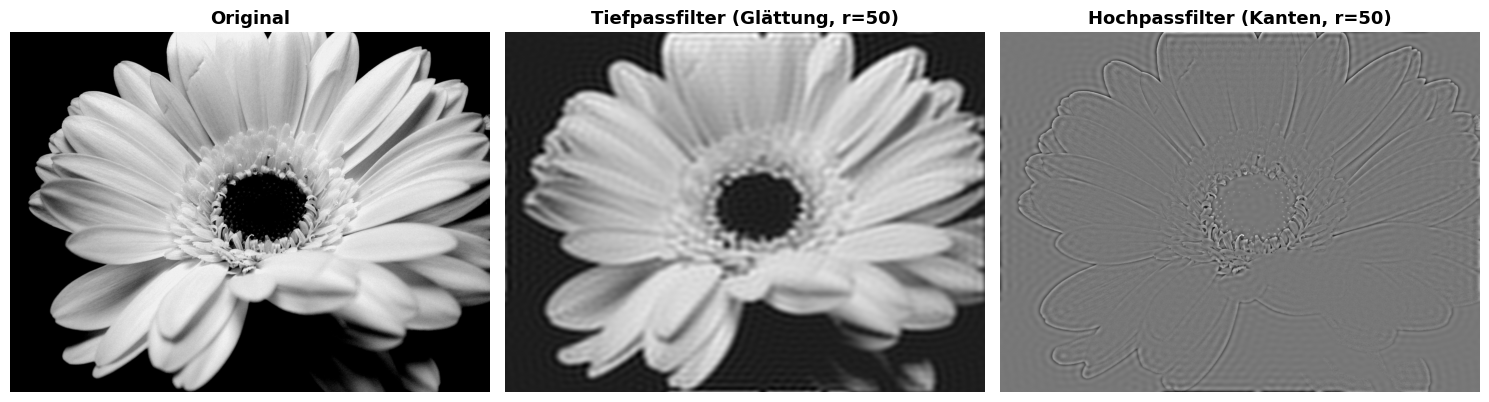

In [8]:
fig2, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original', fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img_lowpass, cmap='gray')
axes[1].set_title(f'Tiefpassfilter (Glättung, r={radius_lowpass})', fontsize=13, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(img_highpass_norm, cmap='gray')
axes[2].set_title(f'Hochpassfilter (Kanten, r={radius_highpass})', fontsize=13, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Erwartete Ergebnisse

**Tiefpassfilter:**
- Weichzeichnung/Glättung des Bildes
- Entfernung von Rauschen und feinen Details
- Anwendung: Rauschunterdrückung, Blur-Effekt

**Hochpassfilter:**
- Kantendetektion
- Hervorhebung von Details und Übergängen
- Anwendung: Kantenerkennung, Schärfung, Texturanalyse